In [1]:
%pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import unicodedata
%matplotlib inline

In [3]:
# run the fetch_cqi.py script first to access the raw csv
df = pd.read_csv('../data/raw/cqi/cqi2023_arabica_coffee_full_table.csv')

In [4]:
print(df.columns)

Index(['coffee_id', 'Country_of_Origin', 'Farm_Name', 'Lot_Number', 'Mill',
       'ICO_Number', 'Company', 'Altitude', 'Region', 'Producer',
       'Number_of_Bags', 'Bag_Weight', 'In_Country_Partner', 'Harvest_Year',
       'Grading_Date', 'Owner', 'Variety', 'Status', 'Processing_Method',
       'Aroma', 'Flavor', 'Aftertaste', 'Acidity', 'Body', 'Balance',
       'Uniformity', 'Clean_Cup', 'Sweetness', 'Overall', 'Defects',
       'Total_Cup_Points', 'Moisture', 'Color', 'Category_One_Defects',
       'Category_Two_Defects', 'Quakers', 'Expiration', 'Certification_Body',
       'Certification_Address', 'Certification_Contact', 'parsed_expiration',
       'parsed_grading_date'],
      dtype='object')


### Retrieve only the useful columns

In [5]:
df = df[['coffee_id', 'Country_of_Origin', 'Altitude', 'Region', 'Harvest_Year', 'Processing_Method',
               'Aroma', 'Flavor', 'Aftertaste', 'Acidity', 'Body', 'Balance', 'Uniformity', 'Clean_Cup', 
               'Sweetness', 'Overall', 'Total_Cup_Points', 'Moisture']]
df.head()

,coffee_id,Country_of_Origin,Altitude,Region,Harvest_Year,Processing_Method,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean_Cup,Sweetness,Overall,Total_Cup_Points,Moisture
0,#647123,Guatemala,1600.0,quiche,2021 / 2022,Washed / Wet,7.83,7.92,7.75,8.00,7.75,7.75,10.0,10.0,10.0,7.92,84.92,0.117
1,#927000,Guatemala,1600.0,Atitlán,2022 / 2023,Washed / Wet,7.58,7.83,7.58,7.75,7.67,7.75,10.0,10.0,10.0,7.75,83.92,0.100
2,#902618,Guatemala,1550.0,Oriente Santa rosa,2022 / 2023,Washed / Wet,7.67,7.83,7.67,7.83,7.75,7.67,10.0,10.0,10.0,7.67,84.08,0.110
3,#781706,Guatemala,1600.0,Atitlán,2022 / 2023,Washed / Wet,7.58,7.92,7.67,7.75,7.83,7.75,10.0,10.0,10.0,7.75,84.25,0.100
4,#237025,Guatemala,1350.0,Huehuetenango,2022 / 2023,Washed / Wet,7.67,7.83,7.75,7.75,7.83,7.75,10.0,10.0,10.0,7.75,84.33,0.092


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1509 entries, 0 to 1508
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   coffee_id          1509 non-null   object 
 1   Country_of_Origin  1508 non-null   object 
 2   Altitude           1279 non-null   float64
 3   Region             1450 non-null   object 
 4   Harvest_Year       1462 non-null   object 
 5   Processing_Method  1352 non-null   object 
 6   Aroma              1509 non-null   float64
 7   Flavor             1509 non-null   float64
 8   Aftertaste         1509 non-null   float64
 9   Acidity            1509 non-null   float64
 10  Body               1509 non-null   float64
 11  Balance            1509 non-null   float64
 12  Uniformity         1509 non-null   float64
 13  Clean_Cup          1509 non-null   float64
 14  Sweetness          1509 non-null   float64
 15  Overall            1509 non-null   float64
 16  Total_Cup_Points   1509 

In [7]:
df['Country_of_Origin'].unique()

array(['Guatemala', 'Brazil', 'Honduras', 'Colombia', 'Vietnam',
       'El Salvador', 'Madagascar', 'Indonesia', 'Taiwan', 'Ethiopia',
       'Panama', 'Costa Rica', 'Tanzania, United Republic Of', 'Kenya',
       'China', 'Philippines', 'United States', 'Mexico', 'Zambia',
       'Nicaragua', 'Cote d?Ivoire', 'Burundi', 'Peru', 'Ecuador',
       'Myanmar', 'United States (Puerto Rico)', 'Rwanda',
       'United States (Hawaii)', 'India', 'Thailand', 'Haiti',
       'Papua New Guinea', nan, 'Laos', 'Japan', 'Uganda', 'Malawi',
       'Mauritius'], dtype=object)

In [8]:
df['Region'].unique()

array(['quiche', 'Atitlán', 'Oriente Santa rosa', 'Huehuetenango',
       'Sierra de las minas', 'Santa Rosa', 'Antigua', 'Região Vulcânica',
       'Sul de Minas', 'los planes de santa maria la paz',
       'Los Planes de Santa Maria, La Paz', 'Marcala',
       'Centro, Lagunetillas-Ajuterique, Comayagua', 'Cauca',
       'Popayán Cauca', 'HUILA', 'Huila', 'Lam Dong Province', nan,
       'Volcan Chinchontepek, San Vicente, El Salvador',
       'Apaneca - Ilamatepec', 'Itasy', 'Sumatra', 'Aceh Tengah',
       'Shibi, Gukeng Township, Yunlin County 郵遞區號 , Taiwan (R.O.C.)',
       'Caoling , Gukeng Township, Yunlin County',
       'Gukeng Township, Yunlin County', 'Ethiopia', 'Boquete',
       'Corralillo Tarrazu', 'occidente', 'Tarrazu', 'Mbeya',
       'KILIMANJARO', 'ARUSHA', 'Arusha', 'Central', 'Sidama', 'yunnan',
       'corillera administrative', 'davao city, region 11',
       'central america', 'chiapas', 'kiambu', 'la concordia, chiapas',
       'ataco, apaneca - ilamatepec mo

### Clean the region column

In [9]:
def clean_region(s, country):
    if pd.isna(s):
        return pd.NA
    t = unicodedata.normalize("NFKD", str(s))
    t = "".join(ch for ch in t if not unicodedata.combining(ch)).lower()   # drop accents, keep CJK
    t = re.sub(r"\(.*?\)", "", t)                                          # drop (R.O.C.) etc.
    t = re.sub(r"[^\w, ]+", " ", t)                                        # punctuation -> space
    parts = [re.sub(r"\s+", " ", p).strip() for p in t.split(",")]
    parts = [p for p in parts if p and p != str(country).lower()]          # drop trailing country name
    return ", ".join(parts) or pd.NA

df["Region_Clean"] = [clean_region(r, c) for r, c in zip(df["Region"], df["Country_of_Origin"])]

In [10]:
df['Region_Clean'].unique()

array(['quiche', 'atitlan', 'oriente santa rosa', 'huehuetenango',
       'sierra de las minas', 'santa rosa', 'antigua', 'regiao vulcanica',
       'sul de minas', 'los planes de santa maria la paz',
       'los planes de santa maria, la paz', 'marcala',
       'centro, lagunetillas ajuterique, comayagua', 'cauca',
       'popayan cauca', 'huila', 'lam dong province', <NA>,
       'volcan chinchontepek, san vicente', 'apaneca ilamatepec', 'itasy',
       'sumatra', 'aceh tengah',
       'shibi, gukeng township, yunlin county 郵遞區號',
       'caoling, gukeng township, yunlin county',
       'gukeng township, yunlin county', 'boquete', 'corralillo tarrazu',
       'occidente', 'tarrazu', 'mbeya', 'kilimanjaro', 'arusha',
       'central', 'sidama', 'yunnan', 'corillera administrative',
       'davao city, region 11', 'central america', 'chiapas', 'kiambu',
       'la concordia, chiapas',
       'ataco, apaneca ilamatepec mountain range', 'sidamo',
       'mubuyu estate', 'tolima',
       

In [11]:
df['Harvest_Year'].value_counts()

Harvest_Year
2012                        352
2014                        226
2013                        170
2015                        125
2016                        122
2021 / 2022                  89
2017                         68
2022                         48
2022 / 2023                  44
2013/2014                    29
2015/2016                    28
2011                         26
2017 / 2018                  20
2014/2015                    19
2021                         13
2009/2010                    12
2010                         10
2016 / 2017                   6
2010-2011                     6
4T/10                         4
4T/2010                       3
Mar-10                        3
Mayo a Julio                  3
2009-2010                     3
Abril - Julio                 2
08/09 crop                    2
2023                          2
Jan-11                        2
2011/2012                     2
2018 / 2019                   1
2009 / 2010                

### Parse the harvest year column

In [12]:
def parse_harvest_year(v):
    if pd.isna(v):
        return pd.Series([pd.NA, pd.NA])
    s = str(v).strip().lower()
    yrs = re.findall(r"20\d{2}", s)                        # 2021 / 2022, 4T72010, Spring 2011 ...
    if not yrs:
        if m := re.fullmatch(r"(\d{2})/(\d{2}) crop", s):  # 08/09 crop
            yrs = [2000 + int(m[1]), 2000 + int(m[2])]
        elif m := re.fullmatch(r"\dt/(\d{2})", s):         # 4T/10
            yrs = [2000 + int(m[1])]
        elif m := re.search(r"[a-z]{3}-(\d{2})$", s):      # Mar-10, 23-Jul-10 (Excel-mangled)
            yrs = [2000 + int(m[1])]
    yrs = [int(y) for y in yrs]
    return pd.Series([min(yrs), max(yrs)] if yrs else [pd.NA, pd.NA])

df[["Harvest_Year_Start", "Harvest_Year_End"]] = df["Harvest_Year"].apply(parse_harvest_year)
df[["Harvest_Year_Start", "Harvest_Year_End"]] = df[["Harvest_Year_Start", "Harvest_Year_End"]].astype("Int64")

In [13]:
df[['Harvest_Year_End']].value_counts()

Harvest_Year_End
2012                354
2014                255
2013                170
2016                150
2015                144
2022                137
2017                 75
2023                 46
2010                 43
2011                 40
2018                 21
2021                 13
2009                  3
2019                  1
Name: count, dtype: int64

In [14]:
df.loc[(df['Altitude'].isnull())&(df['Region_Clean'].notnull()), 'Region_Clean']

64             antigua
78          san rafael
94        bener meriah
95             huanuco
97                puno
             ...      
1204    eastern uganda
1228            arusha
1256             moshi
1303                台灣
1358          jinotega
Name: Region_Clean, Length: 169, dtype: object

<Axes: xlabel='Altitude', ylabel='Count'>

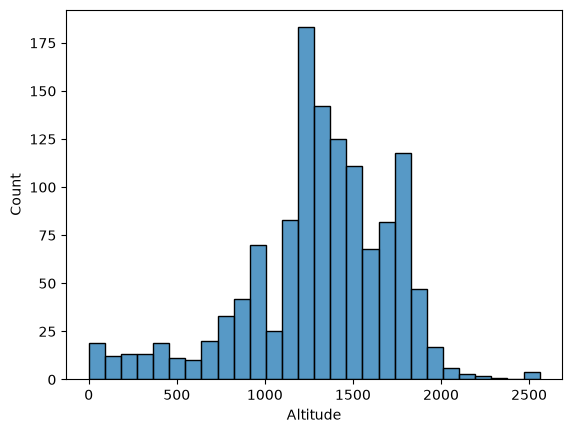

In [15]:
sns.histplot(df['Altitude'])

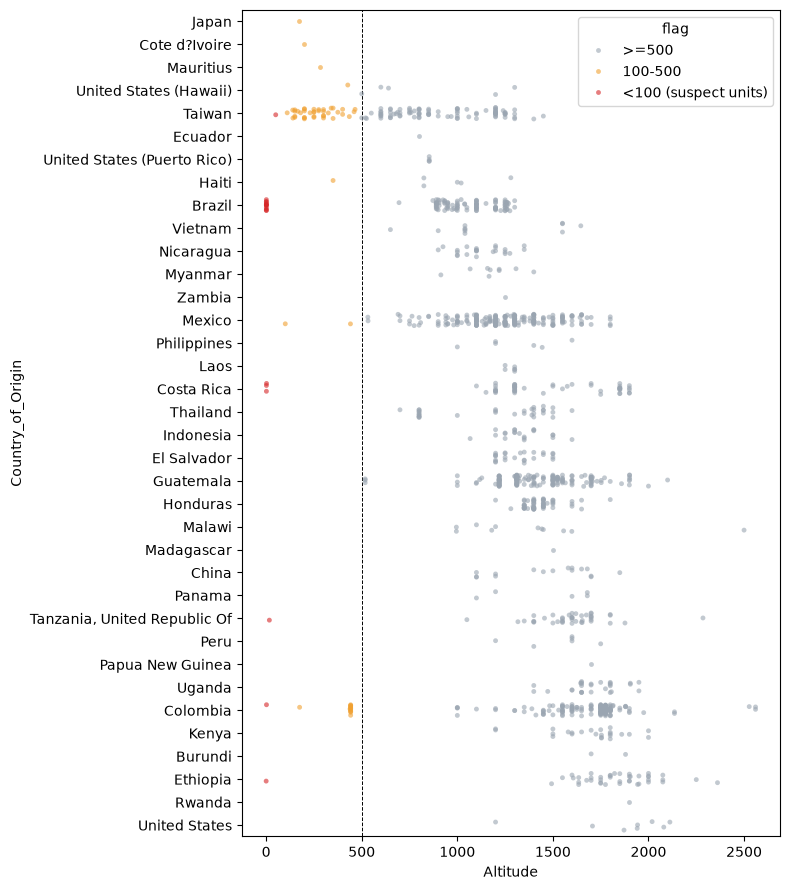

In [16]:
d = df[df["Altitude"].notna()].copy()
order = d.groupby("Country_of_Origin")["Altitude"].median().sort_values().index
d["flag"] = np.where(d["Altitude"] < 100, "<100 (suspect units)",
            np.where(d["Altitude"] < 500, "100-500", ">=500"))

fig, ax = plt.subplots(figsize=(8, 9))
sns.stripplot(data=d, y="Country_of_Origin", x="Altitude", hue="flag", order=order,
              size=3.5, alpha=.6, jitter=.25, ax=ax,
              palette={">=500": "#9aa5b1", "100-500": "#f0a030", "<100 (suspect units)": "#d62728"})
ax.axvline(500, ls="--", c="k", lw=.7)
plt.tight_layout(); plt.show()

### Set outliers to null and impute all nulls with median

In [17]:
g = df.groupby("Country_of_Origin")["Altitude"]
med = g.transform("median")
mad = g.transform(lambda s: (s - s.median()).abs().median()) * 1.4826       # get the mean absolute deviation
n   = g.transform("count")
df["Altitude_Outlier"] = ((df["Altitude"] - med) / mad < -3) & (n >= 10)    # 3 MAD per country for countries with >= rows
df.loc[df["Altitude_Outlier"], "Altitude"] = np.nan                         # set outlier altitudes to null

reg  = df["Region_Clean"].str.lower().str.strip()
need = df["Altitude"].isna() & reg.notna()
by_region  = df["Altitude"].groupby([df["Country_of_Origin"], reg]).transform("median")
by_country = df.groupby("Country_of_Origin")["Altitude"].transform("median")

df["Altitude_Imputed"] = need & (by_region.notna() | by_country.notna())
df.loc[need, "Altitude"] = by_region[need].fillna(by_country[need])         # impute nulls with region or country's median

c:\Users\nwjh2\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
c:\Users\nwjh2\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


<Axes: xlabel='Altitude', ylabel='Count'>

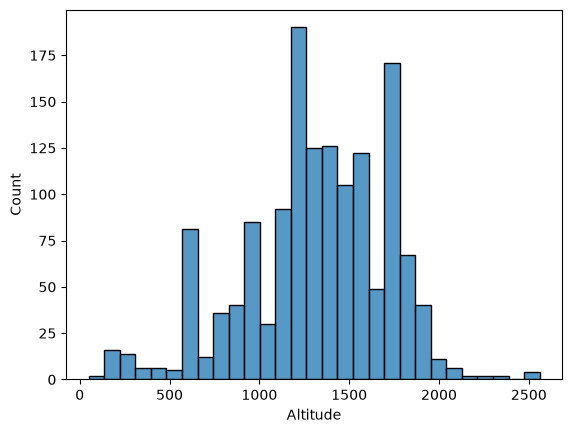

In [18]:
sns.histplot(df['Altitude'])

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1509 entries, 0 to 1508
Data columns (total 23 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   coffee_id           1509 non-null   object 
 1   Country_of_Origin   1508 non-null   object 
 2   Altitude            1447 non-null   float64
 3   Region              1450 non-null   object 
 4   Harvest_Year        1462 non-null   object 
 5   Processing_Method   1352 non-null   object 
 6   Aroma               1509 non-null   float64
 7   Flavor              1509 non-null   float64
 8   Aftertaste          1509 non-null   float64
 9   Acidity             1509 non-null   float64
 10  Body                1509 non-null   float64
 11  Balance             1509 non-null   float64
 12  Uniformity          1509 non-null   float64
 13  Clean_Cup           1509 non-null   float64
 14  Sweetness           1509 non-null   float64
 15  Overall             1509 non-null   float64
 16  Total_

In [20]:
df.describe()

,Altitude,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean_Cup,Sweetness,Overall,Total_Cup_Points,Moisture,Harvest_Year_Start,Harvest_Year_End
count,1447.000000,1509.000000,1509.000000,1509.000000,1509.000000,1509.000000,1509.000000,1509.000000,1509.000000,1509.000000,1509.000000,1509.000000,1509.000000,1452.0,1452.0
mean,1317.048818,7.585991,7.548615,7.425964,7.554758,7.534791,7.535726,9.853930,9.855017,9.915964,7.522730,82.333612,0.091294,2014.625344,2014.80854
std,399.876117,0.371316,0.393472,0.396179,0.371626,0.347488,0.391863,0.525392,0.721136,0.495834,0.459661,3.378540,0.045368,3.21053,3.389567
min,50.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2008.0,2009.0
25%,1100.000000,7.420000,7.330000,7.250000,7.330000,7.330000,7.330000,10.000000,10.000000,10.000000,7.330000,81.420000,0.098000,2012.0,2012.0
50%,1311.000000,7.580000,7.580000,7.420000,7.580000,7.500000,7.580000,10.000000,10.000000,10.000000,7.500000,82.670000,0.110000,2014.0,2014.0
75%,1600.000000,7.750000,7.750000,7.670000,7.750000,7.750000,7.750000,10.000000,10.000000,10.000000,7.750000,83.830000,0.120000,2016.0,2016.0
max,2560.000000,8.750000,8.830000,8.670000,8.750000,8.580000,8.750000,10.000000,10.000000,10.000000,10.000000,90.580000,0.280000,2023.0,2023.0


In [21]:
df = df.drop(columns=["Region", "Harvest_Year"])
df.head()

,coffee_id,Country_of_Origin,Altitude,Processing_Method,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,...,Clean_Cup,Sweetness,Overall,Total_Cup_Points,Moisture,Region_Clean,Harvest_Year_Start,Harvest_Year_End,Altitude_Outlier,Altitude_Imputed
0,#647123,Guatemala,1600.0,Washed / Wet,7.83,7.92,7.75,8.00,7.75,7.75,...,10.0,10.0,7.92,84.92,0.117,quiche,2021,2022,False,False
1,#927000,Guatemala,1600.0,Washed / Wet,7.58,7.83,7.58,7.75,7.67,7.75,...,10.0,10.0,7.75,83.92,0.100,atitlan,2022,2023,False,False
2,#902618,Guatemala,1550.0,Washed / Wet,7.67,7.83,7.67,7.83,7.75,7.67,...,10.0,10.0,7.67,84.08,0.110,oriente santa rosa,2022,2023,False,False
3,#781706,Guatemala,1600.0,Washed / Wet,7.58,7.92,7.67,7.75,7.83,7.75,...,10.0,10.0,7.75,84.25,0.100,atitlan,2022,2023,False,False
4,#237025,Guatemala,1350.0,Washed / Wet,7.67,7.83,7.75,7.75,7.83,7.75,...,10.0,10.0,7.75,84.33,0.092,huehuetenango,2022,2023,False,False


In [22]:
df.to_csv('../data/processed/cqi_2023_cleaned.csv', index=False)